# Titanic Data Analysis and JSON Handling
Author: Sergii Rostovskyi

This notebook completes Steps 1–7 of the supplied **LAB | Data Manipulation + JSON Handling** instructions using the supplied Titanic CSV. Run all cells in order from this project folder. The notebook exports all passenger records, descriptive statistics, missing-value information, feature comparisons, and four PNG illustrations.

The input is retained unchanged. Missing observations are not guessed: numeric statistics use observed values, missing ages receive the `Unknown` age group, and missing original fields become JSON `null`. These are descriptive associations, not causal conclusions or a trained prediction model.

## Step 1: Setting Up the Project
Use the provided `data/titanic.csv` rather than downloading another version. Install dependencies with `pip install -r requirements.txt` if needed. The `data` and `images` directories are created automatically. The PNG helper renders readable tables and text directly from computed results, so no manual screenshots are needed.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import math
import pandas as pd
from PIL import Image, ImageDraw, ImageFont

DATA_DIR = Path('data')
IMAGE_DIR = Path('images')
DATA_DIR.mkdir(exist_ok=True)
IMAGE_DIR.mkdir(exist_ok=True)
CSV_FILE = DATA_DIR / 'titanic.csv'
JSON_FILE = DATA_DIR / 'titanic_processed.json'
if not CSV_FILE.is_file():
    raise FileNotFoundError('Place the supplied titanic.csv in the data folder.')

def save_illustration(filename, title, sections):
    """Export computed text and tables as a readable PNG, using portable fonts."""
    def font(size):
        for name in ['DejaVuSansMono.ttf', 'C:/Windows/Fonts/consola.ttf']:
            try:
                return ImageFont.truetype(name, size)
            except OSError:
                continue
        return ImageFont.load_default()
    body_font, title_font = font(19), font(27)
    lines = []
    for heading, content in sections:
        lines.extend(['', heading, *str(content).splitlines()])
    probe = ImageDraw.Draw(Image.new('RGB', (1, 1)))
    width = max(1050, int(max(probe.textlength(line, font=body_font) for line in lines)) + 80)
    height = 110 + len(lines) * 28
    image = Image.new('RGB', (width, height), '#f5f7fb')
    draw = ImageDraw.Draw(image)
    draw.rectangle((0, 0, width, 68), fill='#193b60')
    draw.text((30, 18), title, font=title_font, fill='white')
    for index, line in enumerate(lines):
        draw.text((30, 85 + index * 28), line, font=body_font, fill='#172c44')
    path = IMAGE_DIR / filename
    image.save(path)
    print(f'PNG saved: {path}')
    return path

print(f'Input: {CSV_FILE}; JSON output: {JSON_FILE}; illustrations: {IMAGE_DIR}')

Input: data\titanic.csv; JSON output: data\titanic_processed.json; illustrations: images


## Step 2: Importing and Exploring the Data
Read the CSV with pandas, inspect its dimensions, columns, types, and first five rows, and check the identifiers and survival labels. PassengerId is an identifier and Pclass is ordinal; their numeric summaries are included to satisfy the instruction to summarize every numeric column, but should be interpreted accordingly.

In [2]:
df = pd.read_csv(CSV_FILE)
required = {'PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'}
assert required <= set(df.columns)
assert df['PassengerId'].is_unique
assert df['Survived'].isin([0, 1]).all()
assert not df.duplicated().any()
print(f'Dataset loaded successfully! Shape: {df.shape}')
print('Columns:', list(df.columns))
print(df.head().to_string(index=False))
df.info()

Dataset loaded successfully! Shape: (891, 12)
Columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']
 PassengerId  Survived  Pclass                                                Name    Sex  Age  SibSp  Parch           Ticket    Fare Cabin Embarked
           1         0       3                             Braund, Mr. Owen Harris   male 22.0      1      0        A/5 21171  7.2500   NaN        S
           2         1       1 Cumings, Mrs. John Bradley (Florence Briggs Thayer) female 38.0      1      0         PC 17599 71.2833   C85        C
           3         1       3                              Heikkinen, Miss. Laina female 26.0      0      0 STON/O2. 3101282  7.9250   NaN        S
           4         1       1        Futrelle, Mrs. Jacques Heath (Lily May Peel) female 35.0      1      0           113803 53.1000  C123        S
           5         0       3                            Allen, Mr. William Henry 

## Step 3: Calculating Descriptive Statistics
Select every numeric column and calculate its mean, median, and sample standard deviation (`ddof=1`). Pandas excludes missing values from each calculation; the valid count makes the denominator explicit. Calculations precede feature engineering and retain full precision in JSON; displayed tables use three decimal places.

             valid_count    mean  median  sample_std
PassengerId      891.000 446.000 446.000     257.354
Survived         891.000   0.384   0.000       0.487
Pclass           891.000   2.309   3.000       0.836
Age              714.000  29.699  28.000      14.526
SibSp            891.000   0.523   0.000       1.103
Parch            891.000   0.382   0.000       0.806
Fare             891.000  32.204  14.454      49.693
PNG saved: images\01_statistics.png


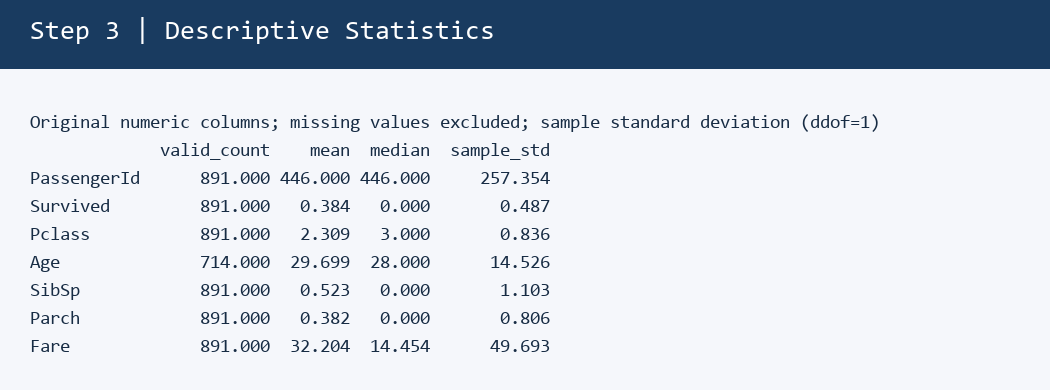

In [3]:
numeric_columns = df.select_dtypes(include='number').columns.tolist()
statistics = df[numeric_columns].agg(['count', 'mean', 'median', 'std']).T
statistics = statistics.rename(columns={'count': 'valid_count', 'std': 'sample_std'})
print(statistics.to_string(float_format=lambda value: f'{value:.3f}'))
save_illustration('01_statistics.png', 'Step 3 | Descriptive Statistics', [
    ('Original numeric columns; missing values excluded; sample standard deviation (ddof=1)',
     statistics.to_string(float_format=lambda value: f'{value:.3f}'))
])

## Step 4: Identifying Missing Values
Count missing observations for every column and divide by the total number of passengers to calculate percentages. Keep all rows and original values. Empty CSV fields already load as pandas missing values; serialization will normalize these to `null`. Avoid imputing age here because imputation would obscure the original missingness and change the age-group comparison.

             missing_count  missing_percent
Cabin                  687           77.104
Age                    177           19.865
Embarked                 2            0.224
PassengerId              0            0.000
Name                     0            0.000
Pclass                   0            0.000
Survived                 0            0.000
Sex                      0            0.000
Parch                    0            0.000
SibSp                    0            0.000
Fare                     0            0.000
Ticket                   0            0.000
PNG saved: images\02_missing_values.png


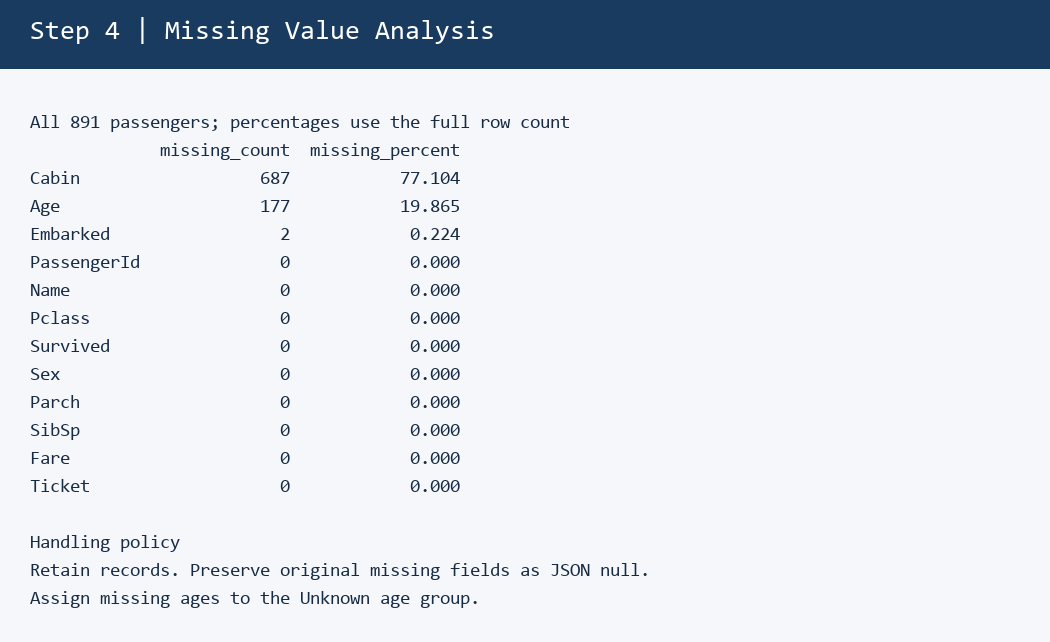

In [4]:
missing_values = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percent': df.isna().mean() * 100
}).sort_values('missing_count', ascending=False)
print(missing_values.to_string(float_format=lambda value: f'{value:.3f}'))
save_illustration('02_missing_values.png', 'Step 4 | Missing Value Analysis', [
    (f'All {len(df)} passengers; percentages use the full row count',
     missing_values.to_string(float_format=lambda value: f'{value:.3f}')),
    ('Handling policy', 'Retain records. Preserve original missing fields as JSON null.\nAssign missing ages to the Unknown age group.')
])

## Step 5: Feature Engineering
Create `FamilySize = SibSp + Parch + 1` and integer `IsAlone = 1` when family size is one, otherwise zero. Categorize observed ages as Child (under 18), Young Adult (18 to under 30), Adult (30 to under 50), or Older Adult (50 and above); missing ages are Unknown.

Compare family-size mean, median, and sample standard deviation by survival outcome. For all three features, show passenger counts and survival rates within each feature category. Rates are proportions from 0 to 1 and include their group sizes so small categories are visible. Family size describes recorded relatives aboard, not necessarily everyone sharing a ticket.

 PassengerId  Age  SibSp  Parch  FamilySize  IsAlone    AgeGroup
           1 22.0      1      0           2        0 Young Adult
           2 38.0      1      0           2        0       Adult
           3 26.0      0      0           1        1 Young Adult
           4 35.0      1      0           2        0       Adult
           5 35.0      0      0           1        1       Adult
           6  NaN      0      0           1        1     Unknown
           7 54.0      0      0           1        1 Older Adult
           8  2.0      3      1           5        0       Child
           9 27.0      0      2           3        0 Young Adult
          10 14.0      1      0           2        0       Child
Family size by survival (0 = did not survive, 1 = survived):
              mean  median       std
Survived                            
0         1.883424     1.0  1.830669
1         1.938596     2.0  1.186076

FamilySize:
            passengers  survived  survival_rate
FamilySize     

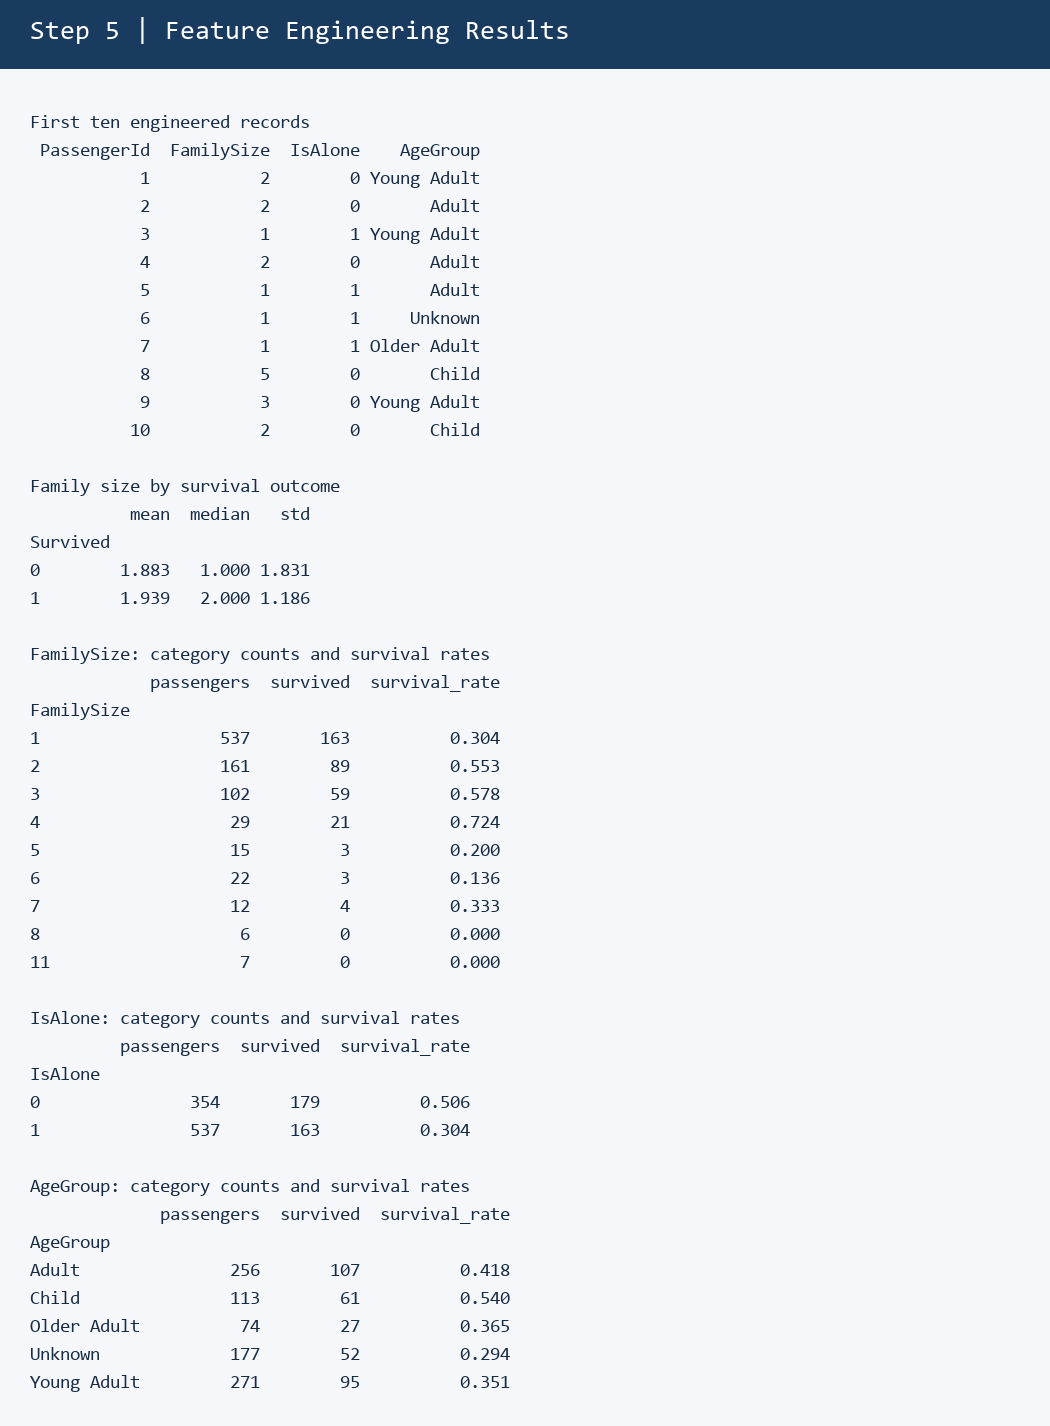

In [5]:
def categorize_age(age):
    """Use the lab's exact age boundaries and retain an explicit missing group."""
    if pd.isna(age):
        return 'Unknown'
    if age < 18:
        return 'Child'
    if age < 30:
        return 'Young Adult'
    if age < 50:
        return 'Adult'
    return 'Older Adult'

df_features = df.copy(deep=True)
df_features['FamilySize'] = df_features['SibSp'] + df_features['Parch'] + 1
df_features['IsAlone'] = (df_features['FamilySize'] == 1).astype(int)
df_features['AgeGroup'] = df_features['Age'].apply(categorize_age)
family_survival = df_features.groupby('Survived')['FamilySize'].agg(['mean', 'median', 'std'])
feature_analysis = {}
for feature in ['FamilySize', 'IsAlone', 'AgeGroup']:
    feature_analysis[feature] = df_features.groupby(feature)['Survived'].agg(
        passengers='size', survived='sum', survival_rate='mean')
print(df_features[['PassengerId', 'Age', 'SibSp', 'Parch', 'FamilySize', 'IsAlone', 'AgeGroup']].head(10).to_string(index=False))
print('Family size by survival (0 = did not survive, 1 = survived):')
print(family_survival.to_string())
for feature, table in feature_analysis.items():
    print(f'\n{feature}:')
    print(table.to_string())
alone_rate = feature_analysis['IsAlone'].loc[1, 'survival_rate']
accompanied_rate = feature_analysis['IsAlone'].loc[0, 'survival_rate']
print(f'Accompanied survival: {accompanied_rate:.1%}; alone survival: {alone_rate:.1%}')
sections = [('First ten engineered records', df_features[['PassengerId', 'FamilySize', 'IsAlone', 'AgeGroup']].head(10).to_string(index=False)),
            ('Family size by survival outcome', family_survival.to_string(float_format=lambda v: f'{v:.3f}'))]
sections += [(f'{feature}: category counts and survival rates', table.to_string(float_format=lambda v: f'{v:.3f}'))
             for feature, table in feature_analysis.items()]
save_illustration('03_feature_engineering.png', 'Step 5 | Feature Engineering Results', sections)

Accompanied passengers have a higher observed survival rate than passengers travelling alone. The family-size table also shows that survival does not increase steadily with family size, and age categories expose differences hidden by a single average age. These comparisons may reflect other factors such as sex and passenger class; missing ages are a separate observational group, not an age estimate.

## Step 6: Creating a Data Export Class
`Passenger` stores all 12 original fields and all three engineered features under descriptive snake_case keys. `TitanicDataset` owns a defensive copy of the data, creates Passenger objects, computes summary statistics, and exports the metadata, original-column statistics, missing-value table, feature comparisons, and complete passenger list. Native Python scalars and `None` ensure portable JSON; `allow_nan=False` rejects non-standard NaN or Infinity tokens.

In [6]:
def native(value):
    """Convert pandas/numpy scalars to strict JSON-compatible Python values."""
    if pd.isna(value):
        return None
    if hasattr(value, 'item'):
        return value.item()
    return value

class Passenger:
    """Represent one passenger, including original and engineered attributes."""
    field_map = {
        'PassengerId': 'passenger_id', 'Survived': 'survived', 'Pclass': 'pclass',
        'Name': 'name', 'Sex': 'sex', 'Age': 'age', 'SibSp': 'sibsp',
        'Parch': 'parch', 'Ticket': 'ticket', 'Fare': 'fare', 'Cabin': 'cabin',
        'Embarked': 'embarked', 'FamilySize': 'family_size',
        'IsAlone': 'is_alone', 'AgeGroup': 'age_group'
    }

    def __init__(self, row):
        for column, attribute in self.field_map.items():
            setattr(self, attribute, native(row[column]))

    def to_dict(self):
        """Expose the passenger attributes as a new dictionary."""
        return {attribute: getattr(self, attribute) for attribute in self.field_map.values()}

class TitanicDataset:
    """Own passenger objects and assemble a complete, auditable JSON export."""
    def __init__(self, dataframe):
        self.dataframe = dataframe.copy(deep=True)
        self.passengers = []
        self._create_passengers()

    def _create_passengers(self):
        self.passengers = [Passenger(row) for _, row in self.dataframe.iterrows()]

    def get_summary_stats(self):
        return {
            'total_passengers': len(self.passengers),
            'survived': sum(p.survived == 1 for p in self.passengers),
            'did_not_survive': sum(p.survived == 0 for p in self.passengers),
            'survival_rate': native(self.dataframe['Survived'].mean()),
            'average_age': native(self.dataframe['Age'].mean()),
            'average_fare': native(self.dataframe['Fare'].mean())
        }

    def to_json(self, filename):
        original = self.dataframe[list(Passenger.field_map)[:12]]
        stats = original.select_dtypes(include='number').agg(['count', 'mean', 'median', 'std']).T
        stats = stats.rename(columns={'count': 'valid_count', 'std': 'sample_std'})
        missing = pd.DataFrame({'missing_count': original.isna().sum(),
                                'missing_percent': original.isna().mean() * 100})
        def table_dict(table):
            return {str(index): {str(key): native(value) for key, value in row.items()}
                    for index, row in table.iterrows()}
        comparisons = {}
        for feature in ['FamilySize', 'IsAlone', 'AgeGroup']:
            table = self.dataframe.groupby(feature)['Survived'].agg(
                passengers='size', survived='sum', survival_rate='mean')
            comparisons[feature] = table_dict(table)
        payload = {
            'metadata': {
                'dataset_name': 'Titanic Passenger Dataset',
                'export_date': datetime.now(timezone.utc).isoformat(),
                'source_file': CSV_FILE.name,
                'schema_version': '1.0',
                'standard_deviation_ddof': 1,
                'missing_value_policy': 'Preserve original missing values as null; missing age group is Unknown.',
                'age_group_boundaries': 'Child: age < 18; Young Adult: 18 <= age < 30; Adult: 30 <= age < 50; Older Adult: age >= 50; Unknown: missing.',
                **self.get_summary_stats()
            },
            'statistics': table_dict(stats),
            'missing_values': table_dict(missing),
            'feature_analysis': comparisons,
            'family_size_by_survival': table_dict(self.dataframe.groupby('Survived')['FamilySize'].agg(['mean', 'median', 'std'])),
            'passengers': [passenger.to_dict() for passenger in self.passengers]
        }
        with Path(filename).open('w', encoding='utf-8') as handle:
            json.dump(payload, handle, indent=2, ensure_ascii=False, allow_nan=False)
        print(f'Exported {len(self.passengers)} passengers to {filename}')
        return payload

dataset = TitanicDataset(df_features)
print(json.dumps(dataset.get_summary_stats(), indent=2))
exported = dataset.to_json(JSON_FILE)

{
  "total_passengers": 891,
  "survived": 342,
  "did_not_survive": 549,
  "survival_rate": 0.3838383838383838,
  "average_age": 29.69911764705882,
  "average_fare": 32.204207968574636
}
Exported 891 passengers to data\titanic_processed.json


## Step 7: Testing and Validation
Reopen the actual file with a strict parser, check required structures and all passenger records against their source rows, and independently check aggregate statistics and missingness. Confirm age boundaries and engineered formulas, including the missing-age case. The final illustration is generated only after these assertions pass.

File: data\titanic_processed.json
Records validated: 891 / 891
Survived: 342; did not survive: 549
Survival rate: 38.384%
Original columns preserved: 12; engineered features: 3
Missing Age / Cabin / Embarked: 177 / 687 / 2
File size: 348,752 bytes
PASS: strict JSON parsing, complete records, source equality, statistics,
missing-value counts, feature rates, formulas, and age boundaries.
PNG saved: images\04_json_export_confirmation.png
Short report saved: report.txt


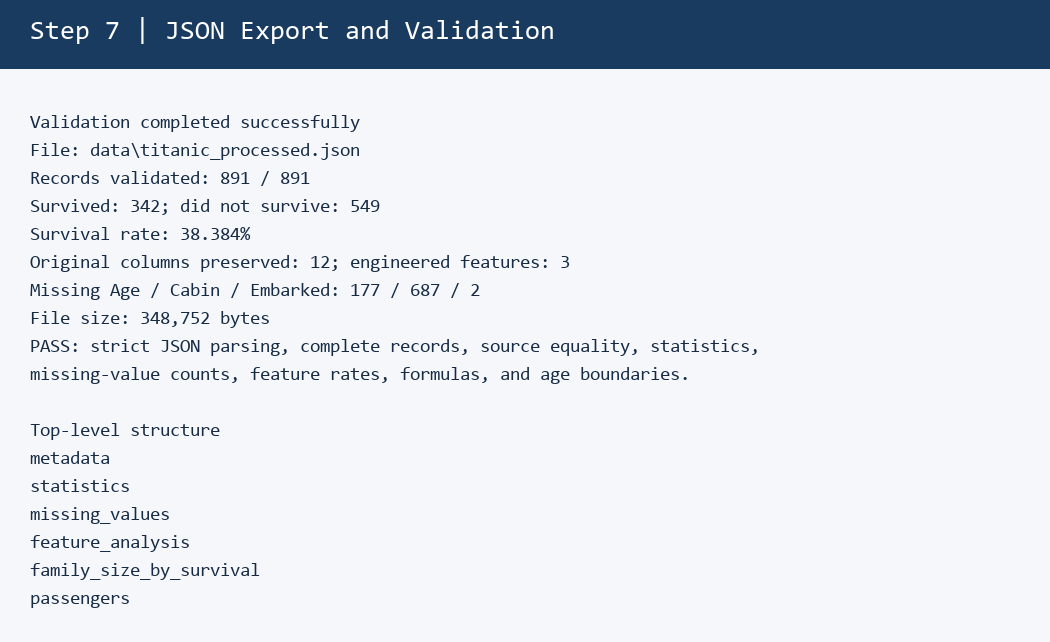

In [7]:
def reject_constant(token):
    raise ValueError(f'Non-standard JSON numeric token: {token}')

with JSON_FILE.open(encoding='utf-8') as handle:
    json_data = json.load(handle, parse_constant=reject_constant)
assert json_data == exported
assert set(json_data) == {'metadata', 'statistics', 'missing_values', 'feature_analysis', 'family_size_by_survival', 'passengers'}
assert len(json_data['passengers']) == len(df) == 891
assert json_data['metadata']['survived'] == 342
assert json_data['metadata']['did_not_survive'] == 549
assert set(json_data['statistics']) == set(numeric_columns)
assert set(json_data['missing_values']) == set(df.columns)
assert len({p['passenger_id'] for p in json_data['passengers']}) == len(df)
for record, (_, source) in zip(json_data['passengers'], df_features.iterrows()):
    assert set(record) == set(Passenger.field_map.values())
    for column, key in Passenger.field_map.items():
        assert record[key] == native(source[column]), (record['passenger_id'], key)
    assert isinstance(record['passenger_id'], int)
    assert record['family_size'] == record['sibsp'] + record['parch'] + 1
    assert record['is_alone'] == int(record['family_size'] == 1)
    assert record['age_group'] == categorize_age(record['age'])
for column in df.columns:
    assert json_data['missing_values'][column]['missing_count'] == int(df[column].isna().sum())
    assert math.isclose(json_data['missing_values'][column]['missing_percent'], df[column].isna().mean() * 100)
for column in numeric_columns:
    for metric, method in [('mean', 'mean'), ('median', 'median'), ('sample_std', 'std')]:
        assert math.isclose(json_data['statistics'][column][metric], float(getattr(df[column], method)()))
for feature, table in feature_analysis.items():
    assert sum(group['passengers'] for group in json_data['feature_analysis'][feature].values()) == len(df)
    for category, row in table.iterrows():
        actual = json_data['feature_analysis'][feature][str(category)]
        assert actual['passengers'] == int(row['passengers'])
        assert actual['survived'] == int(row['survived'])
        assert math.isclose(actual['survival_rate'], float(row['survival_rate']))
assert [categorize_age(x) for x in [None, 17.99, 18, 29.99, 30, 49.99, 50]] == [
    'Unknown', 'Child', 'Young Adult', 'Young Adult', 'Adult', 'Adult', 'Older Adult']
assert df['Age'].isna().sum() == 177
assert df['Cabin'].isna().sum() == 687
assert df['Embarked'].isna().sum() == 2
confirmation = (
    f'File: {JSON_FILE}\nRecords validated: {len(json_data["passengers"])} / {len(df)}\n'
    f'Survived: 342; did not survive: 549\n'
    f'Survival rate: {json_data["metadata"]["survival_rate"]:.3%}\n'
    f'Original columns preserved: 12; engineered features: 3\n'
    f'Missing Age / Cabin / Embarked: 177 / 687 / 2\n'
    f'File size: {JSON_FILE.stat().st_size:,} bytes\n'
    'PASS: strict JSON parsing, complete records, source equality, statistics,\n'
    'missing-value counts, feature rates, formulas, and age boundaries.'
)
print(confirmation)
save_illustration('04_json_export_confirmation.png', 'Step 7 | JSON Export and Validation', [
    ('Validation completed successfully', confirmation),
    ('Top-level structure', '\n'.join(json_data.keys()))
])
report = (
    'I created FamilySize (SibSp + Parch + 1), IsAlone, and AgeGroup, retaining an Unknown group for missing ages. '
    f'These features reveal descriptive survival differences: accompanied passengers survived at {accompanied_rate:.1%} versus {alone_rate:.1%} for those travelling alone, while family-size and age-group tables show additional variation. '
    'Using Passenger and TitanicDataset classes taught me to organize records, reuse summary and export logic, and consistently convert missing values and numeric types into valid JSON.'
)
Path('report.txt').write_text(report + '\n', encoding='utf-8')
print('Short report saved: report.txt')

## Deliverables and Reproducibility
The generated files are `data/titanic_processed.json`, four PNG files in `images`, and the three-sentence `report.txt`. All cells have been executed successfully. Run the notebook again to regenerate the outputs; only the export timestamp changes. No input rows are removed and no original values are imputed.